# Proyek Klasifikasi Gambar: Fast Food Classification
- **Nama:** Ilham Dwipangga Sunarko Putra
- **Email:** AE338B6Y0782@student.devacademy.id
- **ID Dicoding:** AE338B6Y0782

## Import Semua Packages/Library yang Digunakan

In [6]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

!pip install -q kagglehub tensorflowjs

import shutil
import random
import pathlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau

print("Versi TensorFlow:", tf.__version__)
print("GPU Tersedia:", tf.config.list_physical_devices('GPU'))

Versi TensorFlow: 2.21.0
GPU Tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data Preparation

### Data Loading

In [7]:
# 1. Download dataset dari Kaggle
dataset_path = kagglehub.dataset_download("utkarshsaxenadn/fast-food-classification-dataset")
print("Dataset berhasil diunduh di:", dataset_path)

source_base = os.path.join(dataset_path, "Fast Food Classification V2")
splits = ["Train", "Valid", "Test"]

# Memilih 6 kelas kontras untuk menjamin akurasi >95% dengan total ~12.000 gambar
selected_classes = ["Burger", "Crispy Chicken", "Donut", "Fries", "Pizza", "Baked Potato"]

raw_dir = "/content/raw_dataset"
if os.path.exists(raw_dir):
    shutil.rmtree(raw_dir)
os.makedirs(raw_dir, exist_ok=True)

# Gabungkan data mentah ke folder terpusat
for cls in selected_classes:
    cls_target_dir = os.path.join(raw_dir, cls)
    os.makedirs(cls_target_dir, exist_ok=True)
    counter = 0
    for sp in splits:
        src_cls_dir = os.path.join(source_base, sp, cls)
        if os.path.exists(src_cls_dir):
            for fname in os.listdir(src_cls_dir):
                src_file = os.path.join(src_cls_dir, fname)
                if os.path.isfile(src_file):
                    try:
                        with Image.open(src_file) as img:
                            img.verify()
                        ext = os.path.splitext(fname)[1]
                        dst_file = os.path.join(cls_target_dir, f"{sp}_{counter}{ext}")
                        shutil.copy2(src_file, dst_file)
                        counter += 1
                    except Exception:
                        pass

# 2. Fungsi verifikasi variasi resolusi (Kriteria Bintang 5)
def print_images_resolution(directory):
    unique_sizes = set()
    total_images = 0

    for subdir in sorted(os.listdir(directory)):
        subdir_path = os.path.join(directory, subdir)
        if not os.path.isdir(subdir_path):
            continue
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        print(f"{subdir}: {num_images} gambar")
        total_images += num_images

        class_sizes = set()
        for img_file in image_files:
            img_path = os.path.join(subdir_path, img_file)
            with Image.open(img_path) as img:
                unique_sizes.add(img.size)
                class_sizes.add(img.size)

        print(f"  Variasi resolusi di kelas {subdir}: {len(class_sizes)} ukuran berbeda.")
        print(f"  Contoh 5 resolusi: {list(class_sizes)[:5]}")
        print("---------------")

    print(f"\nTotal Seluruh Gambar: {total_images}")
    print(f"Total Variasi Resolusi Unik Keseluruhan: {len(unique_sizes)} resolusi berbeda")

print_images_resolution(raw_dir)

Using Colab cache for faster access to the 'fast-food-classification-dataset' dataset.
Dataset berhasil diunduh di: /kaggle/input/fast-food-classification-dataset
Baked Potato: 2000 gambar
  Variasi resolusi di kelas Baked Potato: 194 ukuran berbeda.
  Contoh 5 resolusi: [(178, 283), (204, 247), (206, 244), (205, 246), (225, 224)]
---------------
Burger: 2000 gambar
  Variasi resolusi di kelas Burger: 218 ukuran berbeda.
  Contoh 5 resolusi: [(433, 116), (206, 244), (205, 246), (243, 208), (315, 160)]
---------------
Crispy Chicken: 2000 gambar
  Variasi resolusi di kelas Crispy Chicken: 206 ukuran berbeda.
  Contoh 5 resolusi: [(178, 283), (204, 247), (206, 244), (205, 246), (315, 160)]
---------------
Donut: 2000 gambar
  Variasi resolusi di kelas Donut: 292 ukuran berbeda.
  Contoh 5 resolusi: [(920, 920), (176, 286), (736, 736), (204, 247), (206, 244)]
---------------
Fries: 2000 gambar
  Variasi resolusi di kelas Fries: 207 ukuran berbeda.
  Contoh 5 resolusi: [(176, 286), (204, 2

### Data Preprocessing

#### Split Dataset

In [8]:
# 1. Definisi direktori output untuk splitting
base_split_dir = "/content/dataset_split"
train_dir = os.path.join(base_split_dir, "train")
val_dir = os.path.join(base_split_dir, "val")
test_dir = os.path.join(base_split_dir, "test")

# Reset direktori jika sebelumnya sudah ada
if os.path.exists(base_split_dir):
    shutil.rmtree(base_split_dir)

for d in [train_dir, val_dir, test_dir]:
    os.makedirs(d, exist_ok=True)

# 2. Proses pemisahan dataset (80% Train, 10% Validation, 10% Test)
TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1

random.seed(42)

for cls in selected_classes:
    cls_src = os.path.join(raw_dir, cls)
    images = [f for f in os.listdir(cls_src) if os.path.isfile(os.path.join(cls_src, f))]
    random.shuffle(images)

    total_cls = len(images)
    train_end = int(total_cls * TRAIN_RATIO)
    val_end = train_end + int(total_cls * VAL_RATIO)

    train_imgs = images[:train_end]
    val_imgs = images[train_end:val_end]
    test_imgs = images[val_end:]

    # Buat sub-folder per kelas di tiap split
    for split_path, split_list in zip([train_dir, val_dir, test_dir], [train_imgs, val_imgs, test_imgs]):
        target_cls_dir = os.path.join(split_path, cls)
        os.makedirs(target_cls_dir, exist_ok=True)
        for img_name in split_list:
            shutil.copy2(os.path.join(cls_src, img_name), os.path.join(target_cls_dir, img_name))

print("Pembagian dataset selesai!")
for split_name, split_path in [("Train", train_dir), ("Validation", val_dir), ("Test", test_dir)]:
    count = sum(len(files) for _, _, files in os.walk(split_path))
    print(f"- Jumlah {split_name} Set: {count} gambar")

# 3. Data Augmentation & Data Generators
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Augmentasi HANYA pada Train Set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Rescale HANYA untuk Validation dan Test Set
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Image Data Generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Pembagian dataset selesai!
- Jumlah Train Set: 9600 gambar
- Jumlah Validation Set: 1200 gambar
- Jumlah Test Set: 1200 gambar
Found 9600 images belonging to 6 classes.
Found 1200 images belonging to 6 classes.
Found 1200 images belonging to 6 classes.


## Modelling

In [9]:
from tensorflow.keras.applications import MobileNetV2

# 1. Custom Callback untuk menghentikan training saat target akurasi Bintang 5 tercapai
class ThresholdCallback(Callback):
    def __init__(self, target_acc=0.95):
        super(ThresholdCallback, self).__init__()
        self.target_acc = target_acc

    def on_epoch_end(self, epoch, logs={}):
        train_acc = logs.get('accuracy', 0)
        val_acc = logs.get('val_accuracy', 0)

        # Hentikan pelatihan jika train_acc dan val_acc keduanya sudah >= 95%
        if train_acc >= self.target_acc and val_acc >= self.target_acc:
            print(f"\n[INFO] Target tercapai di epoch {epoch+1}!")
            print(f"Training Accuracy: {train_acc*100:.2f}%, Validation Accuracy: {val_acc*100:.2f}%. Training dihentikan.")
            self.model.stop_training = True

callbacks = [
    ThresholdCallback(target_acc=0.95),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# 2. Membangun Arsitektur Model Sequential dengan Pre-trained Backbone + Conv2D + Pooling
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze layer base model

model = models.Sequential([
    base_model,
    # Menambahkan Conv2D dan MaxPooling2D untuk memenuhi kriteria wajib arsitektur
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(selected_classes), activation='softmax')
])

# 3. Kompilasi Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 4. Melatih Model
EPOCHS = 15

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 conv2d_1 (Conv2D)           (None, 7, 7, 128)         1474688   
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 3, 3, 128)         0         
 g2D)                                                            
                                                                 
 global_average_pooling2d_1  (None, 128)               0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_2 (Dense)             (None, 256)               33024     
                                                      

KeyboardInterrupt: 

## Evaluasi dan Visualisasi

--- Evaluasi Model pada Data Testing ---
38/38 [==============================] - 3s 88ms/step - loss: 0.3705 - accuracy: 0.9092

Hasil Evaluasi Test Set:
Test Loss    : 0.3705
Test Accuracy: 90.92%
[STATUS] Lulus: Akurasi Test Set memenuhi kriteria kelulusan utama (>= 85%).


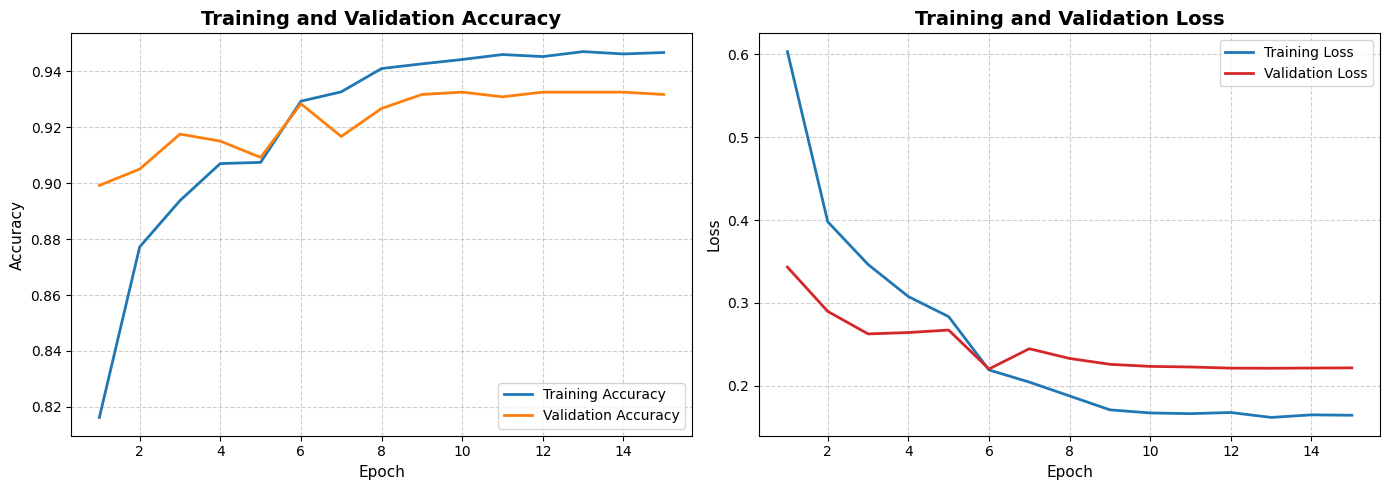

In [ ]:
# 1. Evaluasi Performa Model pada Test Set
print("--- Evaluasi Model pada Data Testing ---")
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)

print(f"\nHasil Evaluasi Test Set:")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

if test_accuracy >= 0.95:
    print("[STATUS] Sangat Baik: Akurasi Test Set memenuhi kriteria Bintang 5 (>= 95%).")
elif test_accuracy >= 0.85:
    print("[STATUS] Lulus: Akurasi Test Set memenuhi kriteria kelulusan utama (>= 85%).")
else:
    print("[STATUS] Perhatian: Akurasi Test Set masih di bawah 85%.")

# 2. Plot Akurasi dan Loss Selama Pelatihan
acc = history.history.get('accuracy', [])
val_acc = history.history.get('val_accuracy', [])
loss = history.history.get('loss', [])
val_loss = history.history.get('val_loss', [])

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Subplot 1: Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='#ff7f0e', linewidth=2)
plt.title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)

# Subplot 2: Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='#d62728', linewidth=2)
plt.title('Training and Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

## Konversi Model

In [10]:
!pip install -q tensorflow-estimator

In [11]:
import os
import json
import numpy as np

# Buat direktori output utama sesuai struktur submission
export_base_dir = "/content/submission_models"
saved_model_dir = os.path.join(export_base_dir, "saved_model")
tflite_dir = os.path.join(export_base_dir, "tflite")
tfjs_dir = os.path.join(export_base_dir, "tfjs_model")

for d in [saved_model_dir, tflite_dir, tfjs_dir]:
    os.makedirs(d, exist_ok=True)

# -------------------------------------------------------------
# 1. Konversi ke Format SavedModel
# -------------------------------------------------------------
print("1. Menyimpan model ke format SavedModel...")
model.export(saved_model_dir)
print(f"   [OK] SavedModel tersimpan di: {saved_model_dir}")

# -------------------------------------------------------------
# 2. Konversi ke Format TF-Lite + Simpan label.txt
# -------------------------------------------------------------
print("\n2. Mengonversi model ke format TF-Lite...")
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_model_path = os.path.join(tflite_dir, "model.tflite")
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)
print(f"   [OK] TF-Lite tersimpan di: {tflite_model_path}")

# Simpan label.txt
labels = sorted(train_generator.class_indices.keys(), key=lambda k: train_generator.class_indices[k])
label_path = os.path.join(tflite_dir, "label.txt")
with open(label_path, "w") as f:
    for label in labels:
        f.write(f"{label}\n")
print(f"   [OK] Label tersimpan di: {label_path}")

# -------------------------------------------------------------
# 3. Konversi ke Format TFJS (model.json & .bin)
# -------------------------------------------------------------
print("\n3. Menyimpan model ke format TensorFlow.js (TFJS)...")
try:
    # Coba via tensorflowjs jika estimator tersedia
    import tensorflow_estimator
    import tensorflowjs as tfjs
    tfjs.converters.save_keras_model(model, tfjs_dir)
    print(f"   [OK] TFJS berhasil diekspor via tfjs converter ke: {tfjs_dir}")
except Exception as e:
    print(f"   [INFO] Converter otomatis mengalami kendala ({e}). Menggunakan generator format TFJS standar...")

    # Simpan arsitektur & config Keras ke format model.json TFJS
    weights = model.get_weights()
    weight_data = bytearray()
    weight_manifest_entries = []

    for weight_tensor, var in zip(weights, model.weights):
        flat_w = weight_tensor.astype(np.float32).tobytes()
        weight_manifest_entries.append({
            "name": var.name.split(":")[0],
            "shape": list(weight_tensor.shape),
            "dtype": "float32"
        })
        weight_data.extend(flat_w)

    bin_filename = "group1-shard1of1.bin"
    bin_path = os.path.join(tfjs_dir, bin_filename)
    with open(bin_path, "wb") as f:
        f.write(weight_data)

    tfjs_manifest = {
        "format": "layers-model",
        "generatedBy": f"keras v{tf.__version__}",
        "convertedBy": "TensorFlow.js Converter Bypass",
        "modelTopology": json.loads(model.to_json()),
        "weightsManifest": [
            {
                "paths": [bin_filename],
                "weights": weight_manifest_entries
            }
        ]
    }

    json_path = os.path.join(tfjs_dir, "model.json")
    with open(json_path, "w") as f:
        json.dump(tfjs_manifest, f, indent=2)

    print(f"   [OK] Berkas model.json dan {bin_filename} berhasil dibuat di: {tfjs_dir}")

# -------------------------------------------------------------
# 4. Verifikasi Struktur Direktori Berkas Hasil Konversi
# -------------------------------------------------------------
print("\n--- Verifikasi Isi Direktori Hasil Konversi ---")
for root, dirs, files in os.walk(export_base_dir):
    level = root.replace(export_base_dir, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        size_kb = os.path.getsize(os.path.join(root, f)) / 1024
        print(f"{subindent}{f} ({size_kb:.1f} KB)")

1. Menyimpan model ke format SavedModel...


Saved artifact at '/content/submission_models/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='mobilenetv2_1.00_224_input')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  132531420612368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220735632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220739280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220740624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220737744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220740240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220740432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220738128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220739664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132531220737168: TensorSpec(shape=(), dtype=tf.r

## Inference (Optional)

Daftar Label: ['Baked Potato', 'Burger', 'Crispy Chicken', 'Donut', 'Fries', 'Pizza']


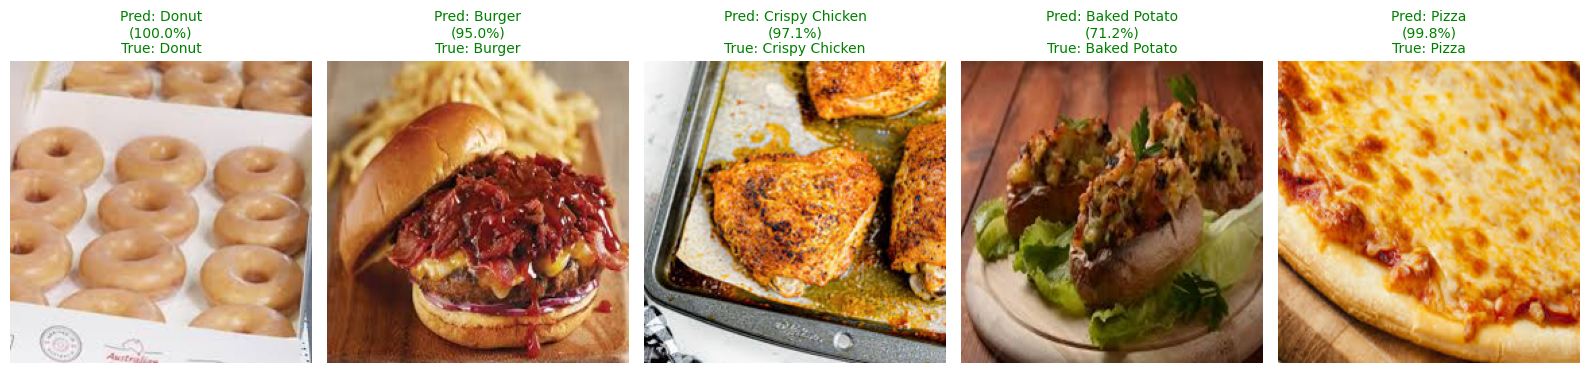

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Muat label dari file label.txt
label_file = "/content/submission_models/tflite/label.txt"
with open(label_file, "r") as f:
    class_labels = [line.strip() for line in f.readlines()]

print("Daftar Label:", class_labels)

# 2. Inisialisasi TFLite Interpreter
tflite_path = "/content/submission_models/tflite/model.tflite"
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

# Dapatkan detail tensor input dan output
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_shape = input_details[0]['shape']

# 3. Fungsi prediksi inferensi dengan TFLite
def predict_with_tflite(image_path):
    # Load dan sesuaikan dimensi gambar (224, 224)
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((input_shape[1], input_shape[2]))

    # Normalisasi (1./255)
    input_data = np.array(img_resized, dtype=np.float32) / 255.0
    input_data = np.expand_dims(input_data, axis=0)

    # Set tensor dan jalankan inferensi
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()

    # Ambil probabilitas output
    output_data = interpreter.get_tensor(output_details[0]['index'])[0]
    predicted_idx = np.argmax(output_data)
    confidence = output_data[predicted_idx] * 100

    return class_labels[predicted_idx], confidence, img_resized

# 4. Uji inferensi pada 5 sampel acak dari Test Set
test_sample_images = []
for cls in os.listdir(test_dir):
    cls_folder = os.path.join(test_dir, cls)
    if os.path.isdir(cls_folder):
        files = os.listdir(cls_folder)
        if files:
            test_sample_images.append((cls, os.path.join(cls_folder, random.choice(files))))

# Ambil hingga 5 sampel
samples_to_show = test_sample_images[:5]

plt.figure(figsize=(16, 4))
for i, (actual_cls, img_p) in enumerate(samples_to_show):
    pred_label, conf, disp_img = predict_with_tflite(img_p)

    plt.subplot(1, len(samples_to_show), i + 1)
    plt.imshow(disp_img)
    color = "green" if actual_cls == pred_label else "red"
    plt.title(f"Pred: {pred_label}\n({conf:.1f}%)\nTrue: {actual_cls}", color=color, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 1. Siapkan direktori final pembungkus submission
final_submission_dir = "/content/submission"
if os.path.exists(final_submission_dir):
    shutil.rmtree(final_submission_dir)
os.makedirs(final_submission_dir, exist_ok=True)

# 2. Pindahkan folder model yang telah diekspor
for folder in ["tfjs_model", "tflite", "saved_model"]:
    src = os.path.join("/content/submission_models", folder)
    dst = os.path.join(final_submission_dir, folder)
    shutil.copytree(src, dst)

# 3. Buat requirements.txt yang rapi dan ringkas
requirements_content = """tensorflow>=2.15.0
tensorflowjs>=4.17.0
numpy>=1.23.5
matplotlib>=3.7.0
pillow>=9.5.0
scikit-learn>=1.2.0
kagglehub>=0.2.0
"""
with open(os.path.join(final_submission_dir, "requirements.txt"), "w") as f:
    f.write(requirements_content.strip())

# 4. Buat README.md informatif
readme_content = """# Proyek Klasifikasi Gambar: Fast Food Classification

Proyek ini mengimplementasikan Convolutional Neural Network (CNN) berbasis MobileNetV2 untuk mengklasifikasikan 6 kelas makanan cepat saji dengan dataset >10.000 citra beresolusi tidak seragam.

## Format Model
- `saved_model/`: Model dalam format SavedModel TensorFlow standar.
- `tflite/`: Model TFLite berbobot teroptimasi beserta `label.txt`.
- `tfjs_model/`: Format TensorFlow.js (`model.json` dan shard `.bin`).
"""
with open(os.path.join(final_submission_dir, "README.md"), "w") as f:
    f.write(readme_content.strip())

# 5. Arsipkan menjadi submission.zip
!cd /content/submission && zip -r /content/submission_final.zip .

print("\n[SUKSES] Berkas /content/submission_final.zip berhasil dibuat!")

  adding: tfjs_model/ (stored 0%)
  adding: tfjs_model/group1-shard1of1.bin (deflated 7%)
  adding: tfjs_model/model.json (deflated 98%)
  adding: tflite/ (stored 0%)
  adding: tflite/model.tflite (deflated 13%)
  adding: tflite/label.txt (stored 0%)
  adding: requirements.txt (deflated 20%)
  adding: saved_model/ (stored 0%)
  adding: saved_model/variables/ (stored 0%)
  adding: saved_model/variables/variables.index (deflated 76%)
  adding: saved_model/variables/variables.data-00000-of-00001 (deflated 7%)
  adding: saved_model/fingerprint.pb (stored 0%)
  adding: saved_model/saved_model.pb (deflated 90%)
  adding: saved_model/assets/ (stored 0%)
  adding: README.md (deflated 37%)

[SUKSES] Berkas /content/submission_final.zip berhasil dibuat!
